
# CFKS Burgers \(\nu=0.01\): publication post-processing

This notebook reproduces the publication figures for the two-stage multiscale CFKS Burgers experiment.

It follows `kapi_onet_publication_style.py` and expects the following files in the same directory:

- `CFKS_BURGERS_MS_NU001_STAGE01_ATTENTION.npz`
- `CFKS_BURGERS_MS_NU001_STAGE02_RESULTS.npz`
- `kapi_onet_publication_style.py`

Outputs are written to a `publication_figures/` subdirectory:

- `CFKS_Burgers_MS_NU001_Publication_2x4.{pdf,png}`
- `CFKS_Burgers_MS_NU001_Solutions_2x2.{pdf,png}`
- `CFKS_Burgers_MS_NU001_Attention.{pdf,png}`
- `CFKS_Burgers_MS_NU001_CollocationLevels.{pdf,png}`
- `CFKS_Burgers_MS_NU001_Table.csv`

The combined \(2\times4\) figure mirrors the predictor / independent-residual / corrector / collocation-enrichment structure used for the transport figures.


In [1]:

from pathlib import Path
import csv
import sys

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import BoundaryNorm, ListedColormap

BASE = Path.cwd()

# Fallback used when the notebook is executed in the ChatGPT environment.
if not (BASE / "CFKS_BURGERS_MS_NU001_STAGE01_ATTENTION.npz").exists():
    if Path("/mnt/data/CFKS_BURGERS_MS_NU001_STAGE01_ATTENTION.npz").exists():
        BASE = Path("/mnt/data")

STAGE1 = BASE / "CFKS_BURGERS_MS_NU001_STAGE01_ATTENTION.npz"
STAGE2 = BASE / "CFKS_BURGERS_MS_NU001_STAGE02_RESULTS.npz"

# Use a dedicated output folder so existing publication files are never overwritten.
OUTDIR = BASE / "publication_figures"
OUTDIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(BASE))
import kapi_onet_publication_style as sty
sty.apply_publication_style()

print("Working directory:", BASE)
print("Output directory :", OUTDIR)
print("Stage 1:", STAGE1.name)
print("Stage 2:", STAGE2.name)


Working directory: /home/vikas/Desktop/ML4PS_paper/CODES/BURGERS_0.01_FINAL
Output directory : /home/vikas/Desktop/ML4PS_paper/CODES/BURGERS_0.01_FINAL/publication_figures
Stage 1: CFKS_BURGERS_MS_NU001_STAGE01_ATTENTION.npz
Stage 2: CFKS_BURGERS_MS_NU001_STAGE02_RESULTS.npz


## Load data and perform consistency checks

In [2]:

def require_keys(archive, keys, label):
    missing = [k for k in keys if k not in archive.files]
    if missing:
        raise KeyError(f"{label} is missing required arrays: {missing}")

if not STAGE1.exists():
    raise FileNotFoundError(STAGE1)
if not STAGE2.exists():
    raise FileNotFoundError(
        f"{STAGE2}\nRun CFKS_BURGERS_MS_NU001_STAGE02_CORRECTOR.ipynb first."
    )

P = np.load(STAGE1, allow_pickle=False)
C = np.load(STAGE2, allow_pickle=False)

require_keys(
    P,
    ("levels", "scores", "probe_rms", "x_edges", "x_transfer",
     "predictor_validation"),
    "Stage 1",
)
require_keys(
    C,
    ("x", "counts", "validation", "n_slabs", "dt"),
    "Stage 2",
)

if abs(float(P["nu"]) - float(C["nu"])) > 1e-14:
    raise ValueError("Stage-1 / Stage-2 viscosity mismatch.")

# Stage 1 intentionally uses a coarser multiscale kernel than Stage 2.
# Therefore the sigma values are NOT required to match.

# The mixture weight should still match unless intentionally changed.
if abs(float(P["eta_local"]) - float(C["eta_local"])) > 1e-14:
    raise ValueError("Stage-1 / Stage-2 mismatch in eta_local.")

print("Stage-1 kernel:")
print(
    f"  global sigmas = "
    f"({float(P['sigma_x_global']):g}, "
    f"{float(P['sigma_t_global']):g})"
)
print(
    f"  local  sigmas = "
    f"({float(P['sigma_x_local']):g}, "
    f"{float(P['sigma_t_local']):g})"
)

print("Stage-2 kernel:")
print(
    f"  global sigmas = "
    f"({float(C['sigma_x_global']):g}, "
    f"{float(C['sigma_t_global']):g})"
)
print(
    f"  local  sigmas = "
    f"({float(C['sigma_x_local']):g}, "
    f"{float(C['sigma_t_local']):g})"
)

if not np.allclose(P["x_transfer"], C["x"], atol=0.0, rtol=0.0):
    raise ValueError("Stage-1 / Stage-2 plotting grids differ.")

print(f"nu = {float(C['nu']):g}")
print(
    "global sigmas = "
    f"({float(C['sigma_x_global']):g}, {float(C['sigma_t_global']):g})"
)
print(
    "local sigmas  = "
    f"({float(C['sigma_x_local']):g}, {float(C['sigma_t_local']):g})"
)
print(f"local-kernel weight eta = {float(C['eta_local']):g}")
print(f"slabs = {int(C['n_slabs'])}, dt = {float(C['dt']):g}")


Stage-1 kernel:
  global sigmas = (0.2, 0.04)
  local  sigmas = (0.06, 0.06)
Stage-2 kernel:
  global sigmas = (0.1, 0.02)
  local  sigmas = (0.015, 0.015)
nu = 0.01
global sigmas = (0.1, 0.02)
local sigmas  = (0.015, 0.015)
local-kernel weight eta = 0.3
slabs = 40, dt = 0.025


## Plotting helpers

In [3]:

def profile(stage, t, prefix="u"):
    tag = {0.25: "025", 0.50: "050", 0.75: "075", 1.00: "100"}[float(t)]
    key = f"{prefix}_t{tag}" if prefix == "u" else f"predictor_t{tag}"
    return np.asarray(stage[key], float)

def reference(stage2, t):
    tag = {0.25: "025", 0.50: "050", 0.75: "075", 1.00: "100"}[float(t)]
    return np.asarray(stage2[f"ref_t{tag}"], float)

def line_panel(ax, x, approx, ref, title, *, legend=False):
    ax.plot(x, ref, ls="--", lw=1.25, color=sty.BLACK, label="Cole--Hopf")
    ax.plot(x, approx, lw=1.35, color=sty.BLUE, label="CFKS")
    ax.set_xlim(-1.0, 1.0)
    ax.set_ylim(-1.08, 1.08)
    ax.set_xlabel(r"$x$")
    ax.set_ylabel(r"$u$")
    ax.set_title(title, fontweight="normal")
    sty.add_major_y_grid(ax)
    if legend:
        ax.legend(loc="upper left")

def heatmap_edges(n_slabs, dt, x_edges):
    t_edges = np.arange(n_slabs + 1, dtype=float) * dt
    return t_edges, np.asarray(x_edges, float)


## Main \(2\times4\) publication figure

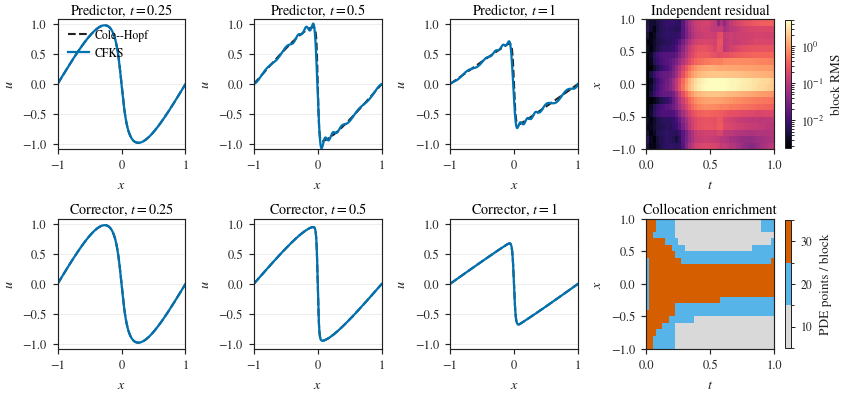

Saved:
  /home/vikas/Desktop/ML4PS_paper/CODES/BURGERS_0.01_FINAL/publication_figures/CFKS_Burgers_MS_NU001_Publication_2x4.pdf
  /home/vikas/Desktop/ML4PS_paper/CODES/BURGERS_0.01_FINAL/publication_figures/CFKS_Burgers_MS_NU001_Publication_2x4.png


In [4]:

x = np.asarray(C["x"], float)
x_edges = np.asarray(P["x_edges"], float)
n_slabs = int(C["n_slabs"])
dt = float(C["dt"])
t_edges, x_edges_hm = heatmap_edges(n_slabs, dt, x_edges)

times = (0.25, 0.50, 1.00)

fig, axes = plt.subplots(
    2, 4,
    figsize=(sty.DOUBLE_COLUMN_WIDTH, 0.47 * sty.DOUBLE_COLUMN_WIDTH),
    constrained_layout=True,
)

for j, tt in enumerate(times):
    pred = np.asarray(P[f"predictor_t{int(round(tt*100)):03d}"], float)
    corr = profile(C, tt, "u")
    ref = reference(C, tt)

    line_panel(
        axes[0, j], x, pred, ref,
        rf"Predictor, $t={tt:g}$",
        legend=(j == 0),
    )
    line_panel(
        axes[1, j], x, corr, ref,
        rf"Corrector, $t={tt:g}$",
    )

R = np.asarray(P["probe_rms"], float).T
norm = sty.positive_lognorm(
    R, floor=1e-8, lower_percentile=1.0, upper_percentile=99.5
)
im = axes[0, 3].pcolormesh(
    t_edges, x_edges_hm, R,
    shading="flat", cmap=sty.CMAP_MAGNITUDE, norm=norm,
)
axes[0, 3].set_xlabel(r"$t$")
axes[0, 3].set_ylabel(r"$x$")
axes[0, 3].set_title("Independent residual", fontweight="normal")
cb = fig.colorbar(im, ax=axes[0, 3], pad=0.02, fraction=0.05)
sty.format_colorbar(cb, r"block RMS")

counts = np.asarray(C["counts"], int).T
cmap = ListedColormap([sty.LIGHT_GRAY, sty.SKY_BLUE, sty.VERMILLION])
norm_levels = BoundaryNorm([5, 15, 25, 35], cmap.N)

im2 = axes[1, 3].pcolormesh(
    t_edges, x_edges_hm, counts,
    shading="flat", cmap=cmap, norm=norm_levels,
)
axes[1, 3].set_xlabel(r"$t$")
axes[1, 3].set_ylabel(r"$x$")
axes[1, 3].set_title("Collocation enrichment", fontweight="normal")
cb2 = fig.colorbar(
    im2, ax=axes[1, 3], pad=0.02, fraction=0.05, ticks=[10, 20, 30]
)
sty.format_colorbar(cb2, "PDE points / block")

for ax in axes.ravel():
    ax.tick_params(which="both", top=False, right=False)

saved_main = sty.save_figure(
    fig, OUTDIR / "CFKS_Burgers_MS_NU001_Publication_2x4"
)
plt.show()

print("Saved:")
for p in saved_main:
    print(" ", p)


## Corrected solution snapshots

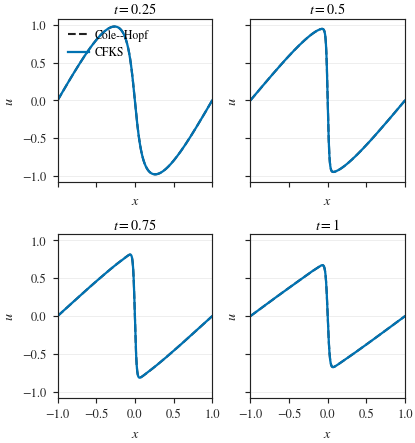

Saved:
  /home/vikas/Desktop/ML4PS_paper/CODES/BURGERS_0.01_FINAL/publication_figures/CFKS_Burgers_MS_NU001_Solutions_2x2.pdf
  /home/vikas/Desktop/ML4PS_paper/CODES/BURGERS_0.01_FINAL/publication_figures/CFKS_Burgers_MS_NU001_Solutions_2x2.png


In [5]:

times = (0.25, 0.50, 0.75, 1.00)

fig, axes = plt.subplots(
    2, 2,
    figsize=(sty.SINGLE_COLUMN_WIDTH, 1.08 * sty.SINGLE_COLUMN_WIDTH),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

for k, (ax, tt) in enumerate(zip(axes.ravel(), times)):
    line_panel(
        ax,
        x,
        profile(C, tt, "u"),
        reference(C, tt),
        rf"$t={tt:g}$",
        legend=(k == 0),
    )

saved_solutions = sty.save_figure(
    fig, OUTDIR / "CFKS_Burgers_MS_NU001_Solutions_2x2"
)
plt.show()

print("Saved:")
for p in saved_solutions:
    print(" ", p)


## Stage-1 independent residual-attention map

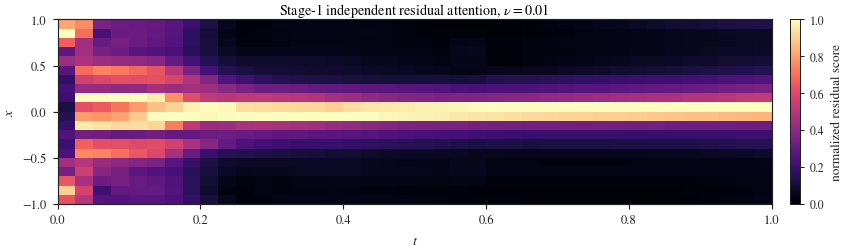

Saved:
  /home/vikas/Desktop/ML4PS_paper/CODES/BURGERS_0.01_FINAL/publication_figures/CFKS_Burgers_MS_NU001_Attention.pdf
  /home/vikas/Desktop/ML4PS_paper/CODES/BURGERS_0.01_FINAL/publication_figures/CFKS_Burgers_MS_NU001_Attention.png


In [6]:

score = np.asarray(P["scores"], float).T

fig, ax = plt.subplots(
    figsize=(sty.DOUBLE_COLUMN_WIDTH, 0.30 * sty.DOUBLE_COLUMN_WIDTH),
    constrained_layout=True,
)
im = ax.pcolormesh(
    t_edges, x_edges_hm, score,
    shading="flat", cmap=sty.CMAP_MAGNITUDE, vmin=0.0, vmax=1.0,
)
ax.set_xlabel(r"$t$")
ax.set_ylabel(r"$x$")
ax.set_title(
    r"Stage-1 independent residual attention, $\nu=0.01$",
    fontweight="normal",
)
cb = fig.colorbar(im, ax=ax, pad=0.015, fraction=0.025)
sty.format_colorbar(cb, "normalized residual score")

saved_attention = sty.save_figure(
    fig, OUTDIR / "CFKS_Burgers_MS_NU001_Attention"
)
plt.show()

print("Saved:")
for p in saved_attention:
    print(" ", p)


## Stage-2 residual-guided collocation density

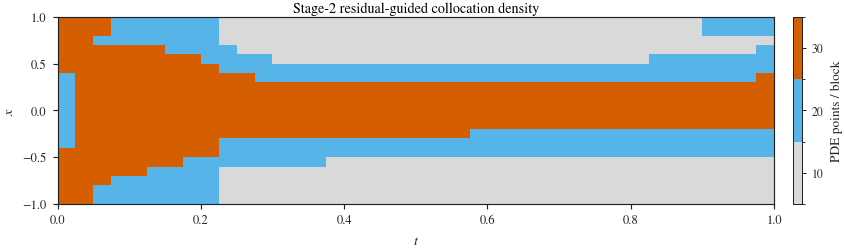

Saved:
  /home/vikas/Desktop/ML4PS_paper/CODES/BURGERS_0.01_FINAL/publication_figures/CFKS_Burgers_MS_NU001_CollocationLevels.pdf
  /home/vikas/Desktop/ML4PS_paper/CODES/BURGERS_0.01_FINAL/publication_figures/CFKS_Burgers_MS_NU001_CollocationLevels.png


In [7]:

fig, ax = plt.subplots(
    figsize=(sty.DOUBLE_COLUMN_WIDTH, 0.30 * sty.DOUBLE_COLUMN_WIDTH),
    constrained_layout=True,
)

cmap = ListedColormap([sty.LIGHT_GRAY, sty.SKY_BLUE, sty.VERMILLION])
norm_levels = BoundaryNorm([5, 15, 25, 35], cmap.N)

im = ax.pcolormesh(
    t_edges, x_edges_hm, counts,
    shading="flat", cmap=cmap, norm=norm_levels,
)
ax.set_xlabel(r"$t$")
ax.set_ylabel(r"$x$")
ax.set_title(
    "Stage-2 residual-guided collocation density",
    fontweight="normal",
)
cb = fig.colorbar(
    im, ax=ax, pad=0.015, fraction=0.025, ticks=[10, 20, 30]
)
sty.format_colorbar(cb, "PDE points / block")

saved_levels = sty.save_figure(
    fig, OUTDIR / "CFKS_Burgers_MS_NU001_CollocationLevels"
)
plt.show()

print("Saved:")
for p in saved_levels:
    print(" ", p)


## Predictor / corrector error table

In [8]:

pred = np.asarray(P["predictor_validation"], float)
corr = np.asarray(C["validation"], float)

rows = []
for p, c in zip(pred, corr):
    if abs(p[0] - c[0]) > 1e-12:
        raise ValueError("Stage-1 and Stage-2 validation times do not match.")
    rows.append([p[0], p[1], p[2], c[1], c[2]])

header = [
    "time",
    "predictor_rmse",
    "predictor_max_error",
    "corrector_rmse",
    "corrector_max_error",
]

table_path = OUTDIR / "CFKS_Burgers_MS_NU001_Table.csv"
with table_path.open("w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(header)
    for row in rows:
        writer.writerow(
            [f"{row[0]:.6g}"] + [f"{v:.12e}" for v in row[1:]]
        )

print(f"{'t':>5}  {'pred RMSE':>12}  {'pred max':>12}  "
      f"{'corr RMSE':>12}  {'corr max':>12}")
print("-" * 63)
for row in rows:
    print(
        f"{row[0]:5.2f}  {row[1]:12.4e}  {row[2]:12.4e}  "
        f"{row[3]:12.4e}  {row[4]:12.4e}"
    )

print("\nSaved:", table_path)

if "Npde_used" in C.files:
    print(
        "Stage-2 PDE points/slab: "
        f"mean={np.mean(C['Npde_used']):.2f}, "
        f"min={np.min(C['Npde_used'])}, "
        f"max={np.max(C['Npde_used'])}"
    )


    t     pred RMSE      pred max     corr RMSE      corr max
---------------------------------------------------------------
 0.25    9.0234e-04    4.6916e-03    2.2121e-04    9.6370e-04
 0.50    4.6472e-02    3.3182e-01    3.4380e-04    2.3202e-03
 0.75    5.9720e-02    4.1633e-01    4.7036e-04    2.6537e-03
 1.00    4.8290e-02    3.0107e-01    4.5491e-04    1.8086e-03

Saved: /home/vikas/Desktop/ML4PS_paper/CODES/BURGERS_0.01_FINAL/publication_figures/CFKS_Burgers_MS_NU001_Table.csv



## Notes

- The multiscale continuum-feature kernel is fixed between predictor and corrector.
- Stage 2 changes the PDE collocation density according to the Stage-1 independent residual attention.
- The plotted reference is the stable Cole--Hopf solution stored by the solver.
- The notebook saves vector PDF and 600-dpi PNG versions of every figure.
